# Filtering Menggunakan Konvolusi menggunakan OpenCV

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt


# Contoh 1

In [ ]:
image = cv2.imread("low-contrast.png", cv2.IMREAD_GRAYSCALE)

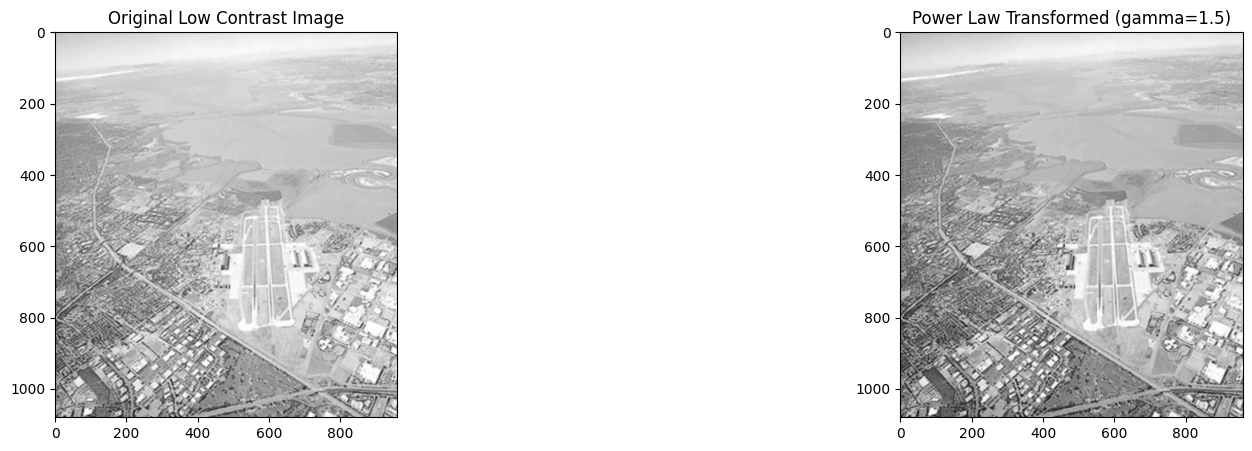

In [ ]:
gamma = 1.5  # You can change this value to adjust contrast

# Apply power law transformation
power_law_transformed = np.array(255 * (image / 255)**gamma, dtype=np.uint8)

cv2.imwrite('low-contrast-enhanced.jpg', power_law_transformed)

# Display the original and transformed images
plt.figure(figsize=[20, 5])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Low Contrast Image")
plt.subplot(122); plt.imshow(power_law_transformed, cmap="gray"); plt.title(f"Power Law Transformed (gamma={gamma})")
plt.show()

Contoh 2

In [ ]:
def piecewise_linear_transform(image, r1, s1, r2, s2):
    # Create a lookup table for the transformation
    lut = np.zeros(256, dtype=np.uint8)

    # Calculate slopes for each segment
    if r1 != 0 and r2 != r1:
        slope1 = s1 / r1
        slope2 = (s2 - s1) / (r2 - r1)
        slope3 = (255 - s2) / (255 - r2)
    else:
        # Handle edge cases to prevent division by zero
        slope1 = 0 if r1 == 0 else s1 / r1
        slope2 = 0 if r2 == r1 else (s2 - s1) / (r2 - r1)
        slope3 = 0 if 255 == r2 else (255 - s2) / (255 - r2)

    # Populate the lookup table
    for i in range(256):
        if i < r1:
            lut[i] = int(slope1 * i)
        elif r1 <= i < r2:
            lut[i] = int(slope2 * (i - r1) + s1)
        else:
            lut[i] = int(slope3 * (i - r2) + s2)

    # Apply the transformation using the lookup table
    transformed_image = cv2.LUT(image, lut)
    return transformed_image


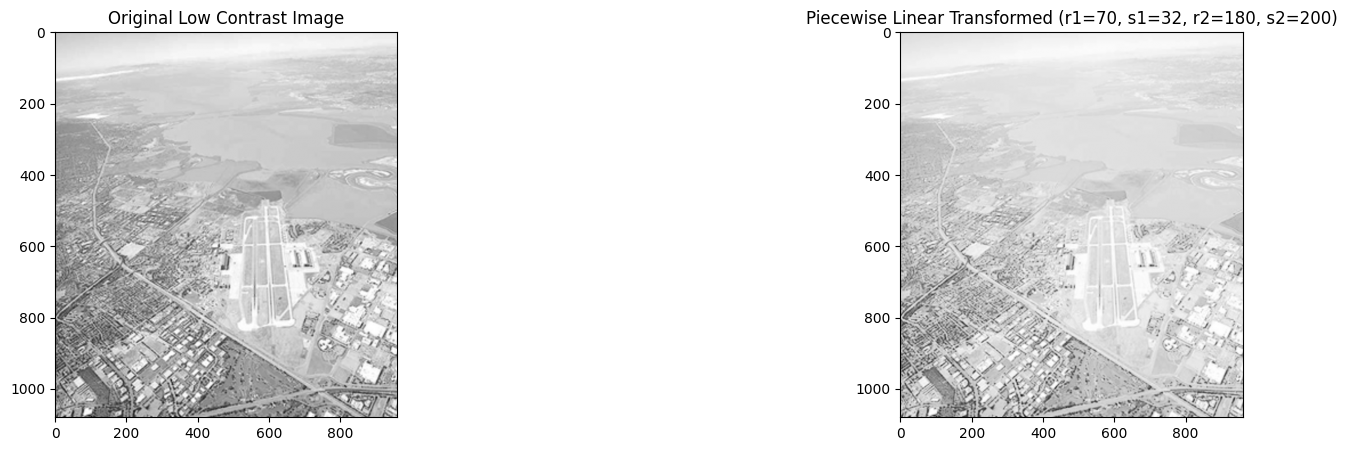

True

In [ ]:
# Define the transformation points (you can adjust these values)
r1, s1 = 70, 32
r2, s2 = 180, 200

# Apply the piecewise linear transformation
piecewise_transformed_image = piecewise_linear_transform(image, r1, s1, r2, s2)

# Display the original and transformed images
plt.figure(figsize=[20, 5])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Low Contrast Image")
plt.subplot(122); plt.imshow(piecewise_transformed_image, cmap="gray"); plt.title(f"Piecewise Linear Transformed (r1={r1}, s1={s1}, r2={r2}, s2={s2})")
plt.show()

cv2.imwrite('low-contrast-piecewise.jpg', piecewise_transformed_image)


Contoh 3

In [ ]:
image = cv2.imread("Piano_Sheet_Music.png", cv2.IMREAD_GRAYSCALE)

print(image.shape)

(854, 1132)


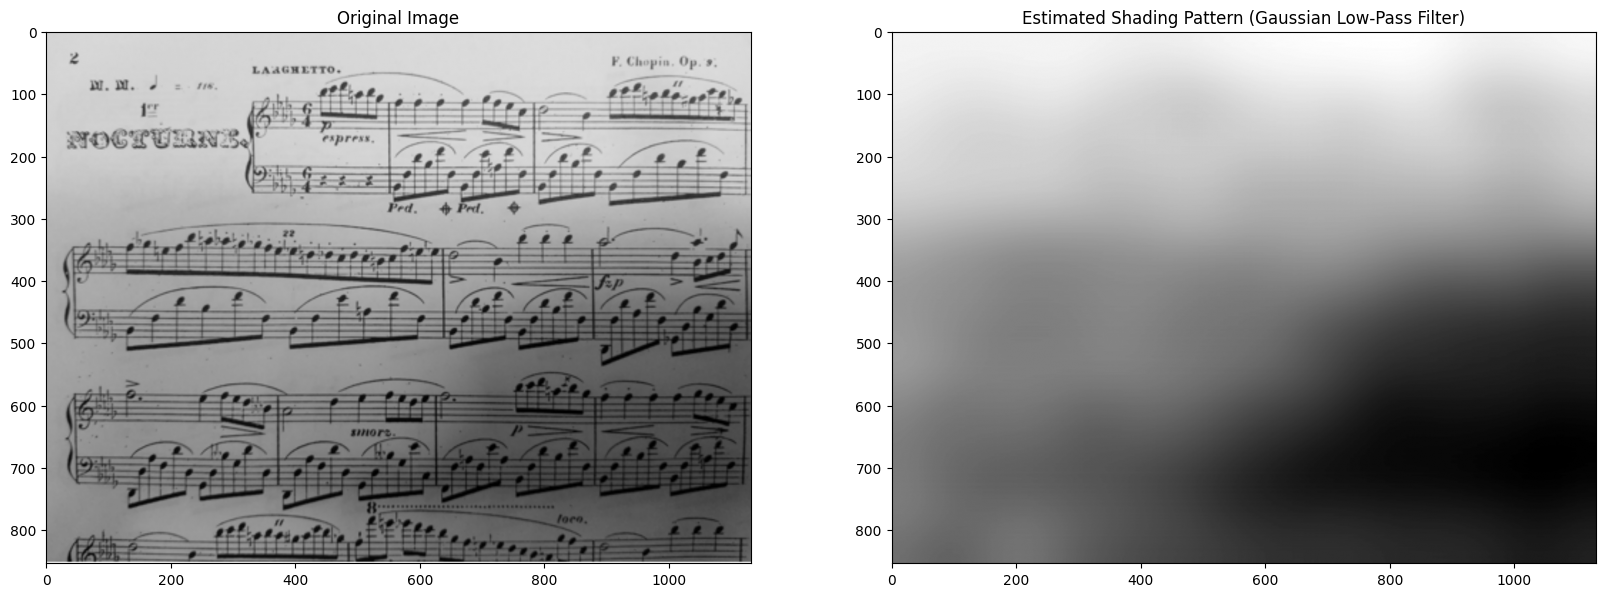

In [ ]:
# Define the Gaussian kernel size and standard deviation
kernel_size = (425, 5515)  # Odd numbers for kernel size are recommended
sigma_x = 50  # Standard deviation in X direction. If 0, it's calculated from kernel size

# Apply Gaussian blur to the image
# This acts as a low-pass filter to estimate the shading patterns
shading_estimate = cv2.GaussianBlur(image, kernel_size, sigma_x)

# Subtract the shading estimate from the original image to get the details
# This step typically enhances features that are not part of the smooth shading
# However, to explicitly 'estimate shading patterns', we often just show the blurred image itself
# If the goal is to *remove* shading, you would subtract it, but here we want to *see* it.

# Display the original image and the estimated shading pattern
plt.figure(figsize=[20, 10])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Image")
plt.subplot(122); plt.imshow(shading_estimate, cmap="gray"); plt.title("Estimated Shading Pattern (Gaussian Low-Pass Filter)")
plt.show()

# cv2.imwrite('piano_shading_estimate.jpg', shading_estimate)

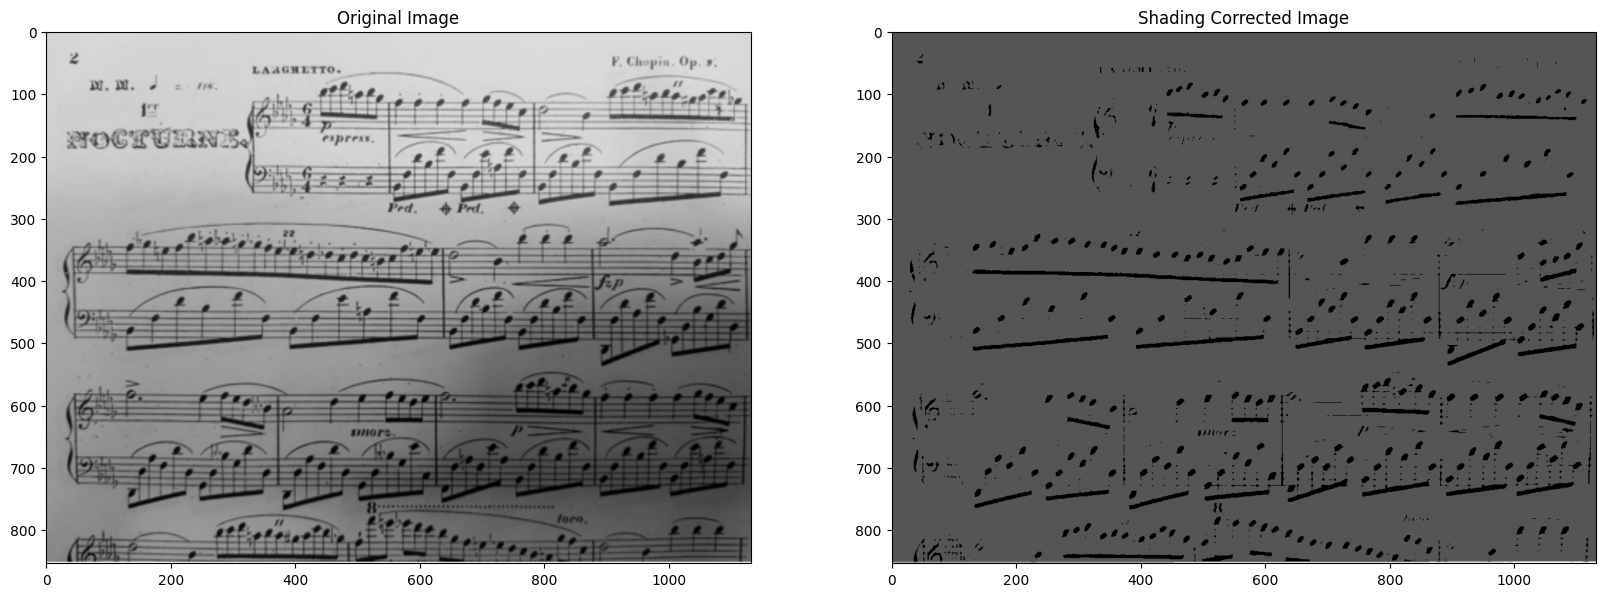

In [ ]:
newimage = cv2.divide(image, shading_estimate)

cv2.imwrite('piano_shading_corrected.jpg', newimage)

plt.figure(figsize=[20, 10])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Image")
plt.subplot(122); plt.imshow(newimage, cmap="gray"); plt.title("Shading Corrected Image")
plt.show()

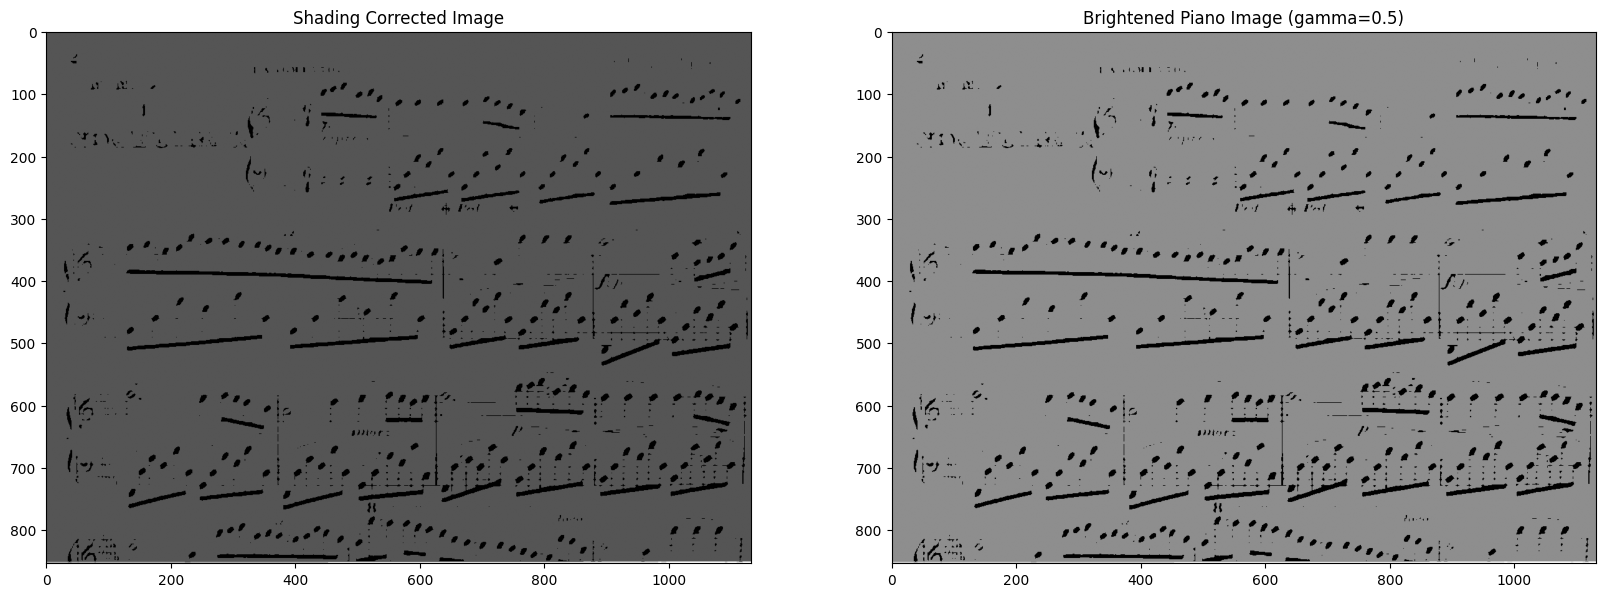

In [ ]:
# Increase brightness using power law transformation on the shading-corrected image
gamma_brightness = 0.5  # Gamma value < 1 to brighten the image

brightened_piano_image = np.array(255 * (newimage / 255)**gamma_brightness, dtype=np.uint8)

plt.figure(figsize=[20, 10])
plt.subplot(121); plt.imshow(newimage, cmap="gray"); plt.title("Shading Corrected Image")
plt.subplot(122); plt.imshow(brightened_piano_image, cmap="gray"); plt.title(f"Brightened Piano Image (gamma={gamma_brightness})")
plt.show()

Contoh 4

(440, 455)


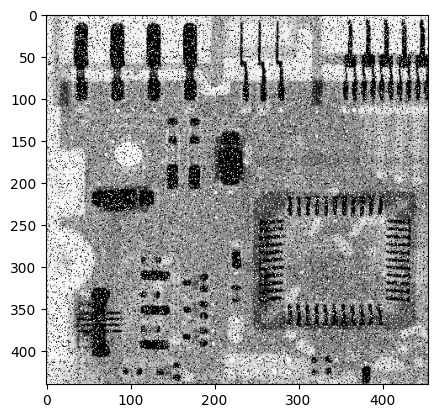

In [ ]:
image = cv2.imread("noisy_board.tif", cv2.IMREAD_GRAYSCALE)

print(image.shape)

plt.imshow(image, cmap="gray");

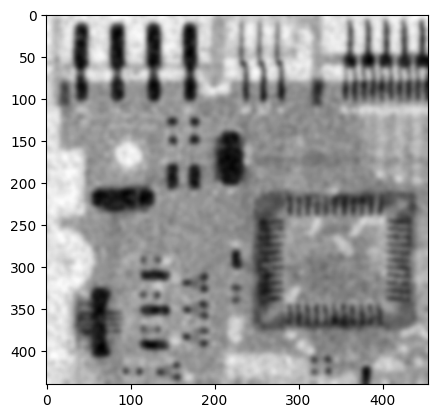

In [ ]:
# Define the Gaussian kernel size and standard deviation
kernel_size = (19, 19)  # Odd numbers for kernel size are recommended
sigma_x = 3  # Standard deviation in X direction. If 0, it's calculated from kernel size

# Apply Gaussian blur to the image
clean_board = cv2.GaussianBlur(image, kernel_size, sigma_x)

plt.imshow(clean_board, cmap="gray");

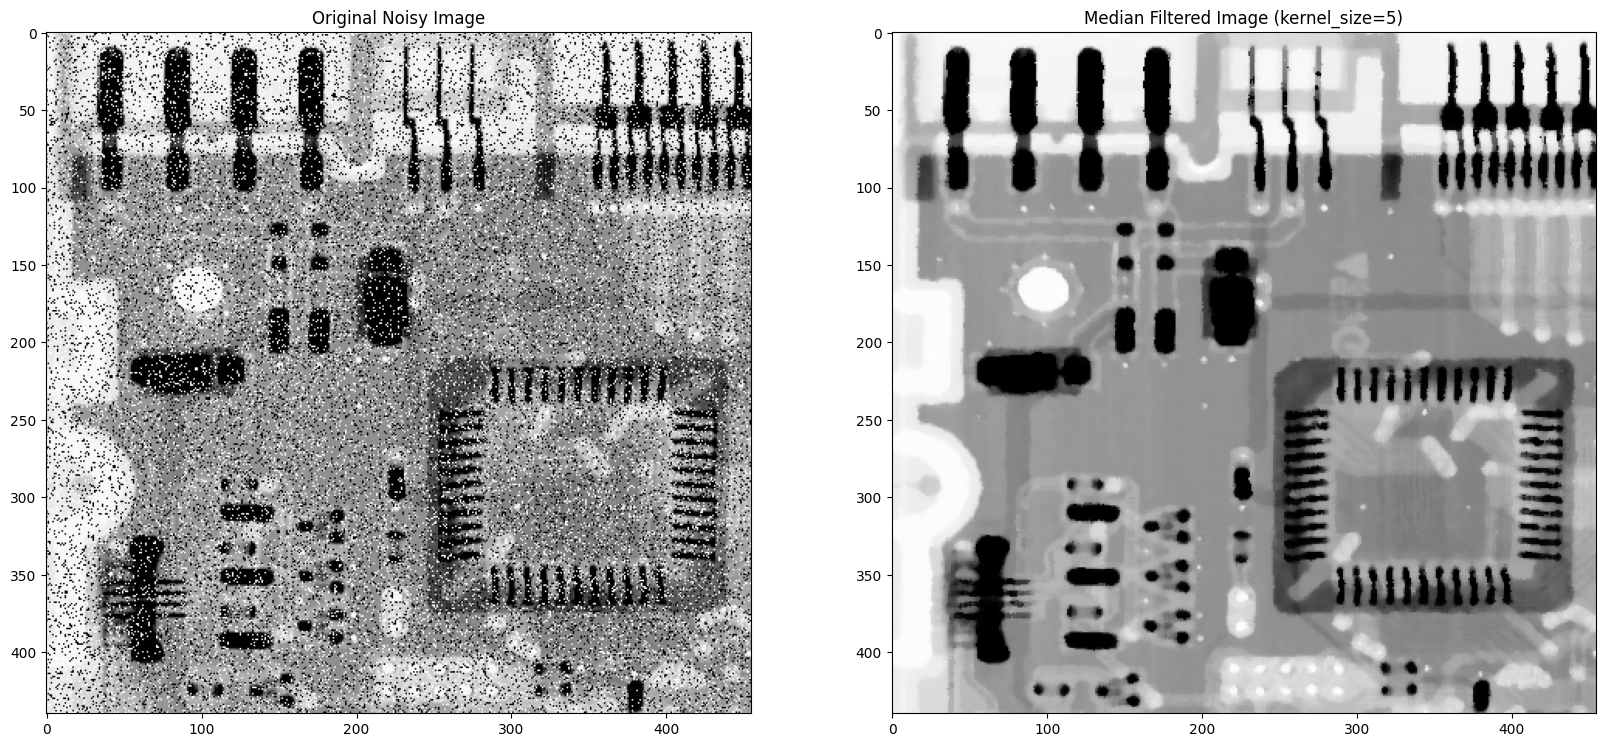

True

In [ ]:
# Define the kernel size for the median filter (must be an odd number)
kernel_size_median = 5

# Apply median blur to the image
median_cleaned_board = cv2.medianBlur(image, kernel_size_median)

plt.figure(figsize=[20, 10])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Noisy Image")
plt.subplot(122); plt.imshow(median_cleaned_board, cmap="gray"); plt.title(f"Median Filtered Image (kernel_size={kernel_size_median})")
plt.show()

cv2.imwrite('median_cleaned_board.jpg', median_cleaned_board)

Contoh Laplacian

(540, 466)


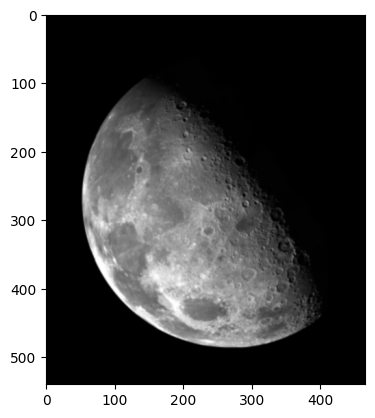

In [ ]:
image = cv2.imread("blurry-moon.tif", cv2.IMREAD_GRAYSCALE)

print(image.shape)

plt.imshow(image, cmap="gray");

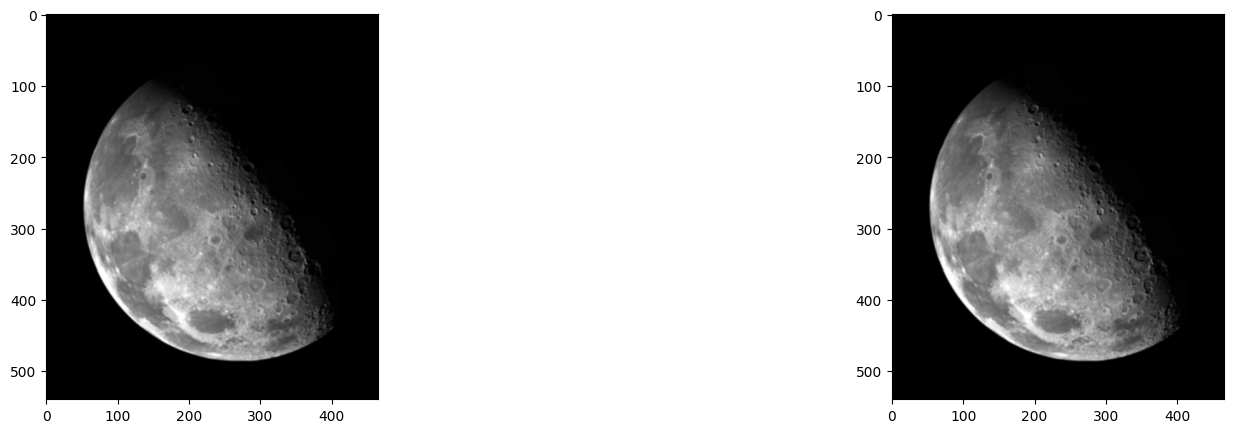

In [ ]:
# Apply identity kernel
kernel1 = np.array([[0, 0, 0],
                    [0, 1, 0],
                    [0, 0, 0]])

identity = cv2.filter2D(src=image, ddepth=-1, kernel=kernel1)
cv2.imwrite('identity.jpg', identity)

plt.figure(figsize=[20, 5])
plt.subplot(121);plt.imshow(image, cmap="gray")
plt.subplot(122);plt.imshow(identity, cmap="gray")


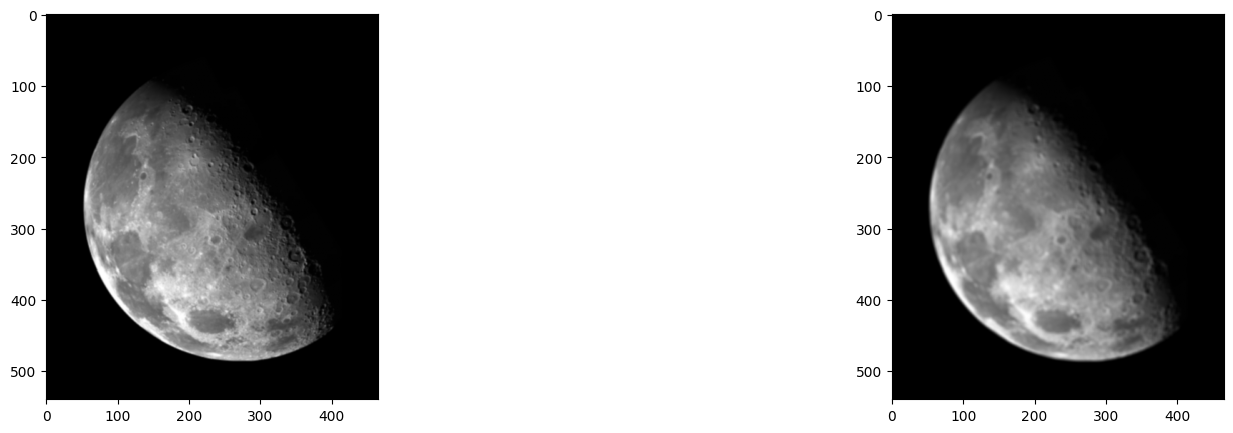

In [ ]:
kernel2 = np.ones((5, 5), np.float32) / 25
img = cv2.filter2D(src=image, ddepth=-1, kernel=kernel2)
cv2.imwrite('blur_blurry-moon.jpg', img)

plt.figure(figsize=[20, 5])
plt.subplot(121);plt.imshow(image, cmap="gray")
plt.subplot(122);plt.imshow(img, cmap="gray")

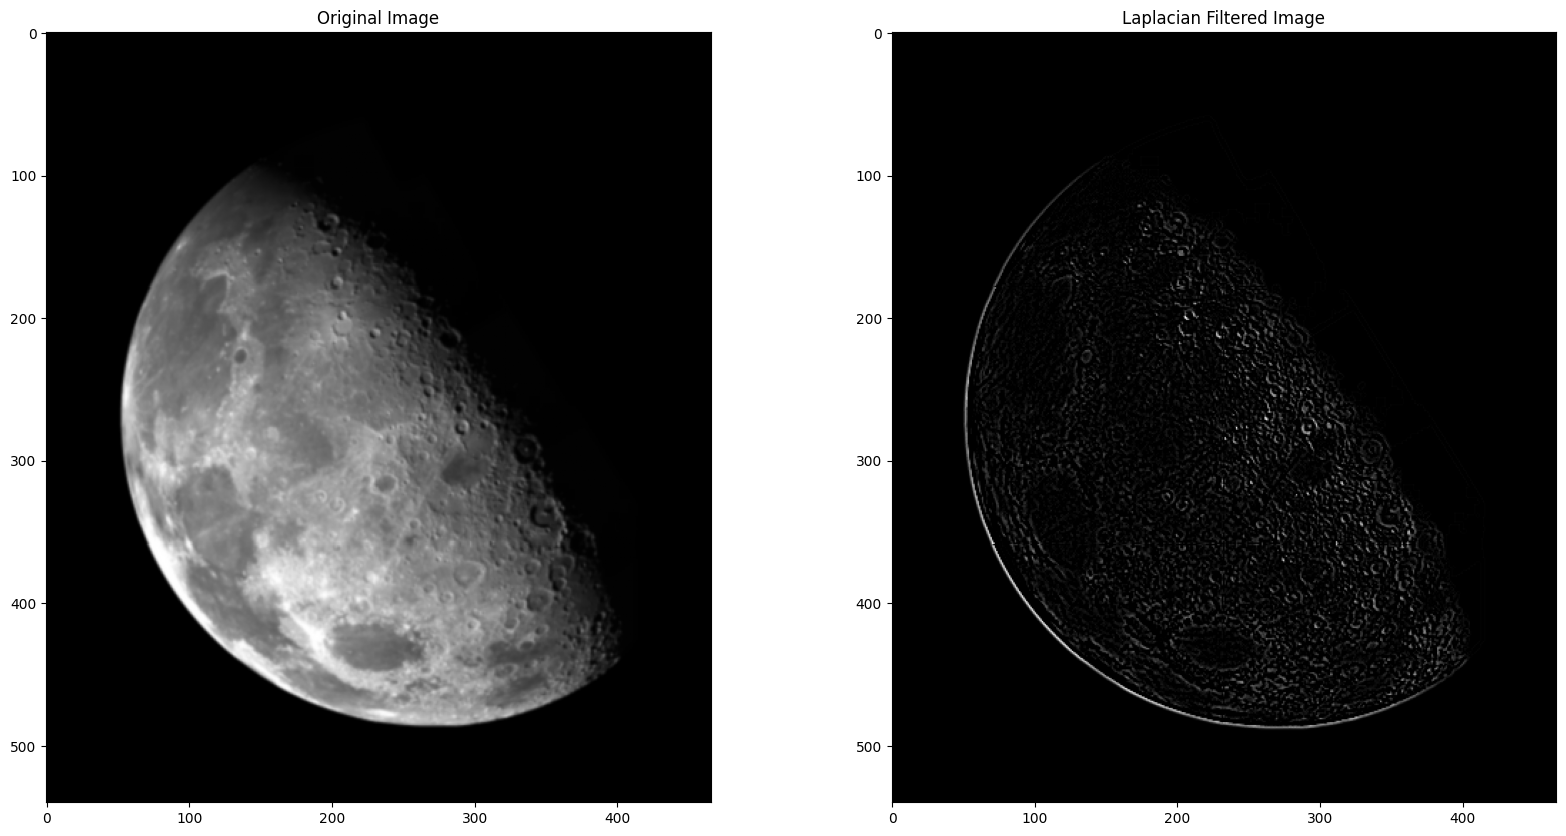

True

In [ ]:
# Define the Laplacian kernel
laplacian_kernel = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
], dtype=np.float32)

# Apply the Laplacian filter to the image
laplacian_image = cv2.filter2D(src=image, ddepth=-1, kernel=laplacian_kernel)

# Display the original and Laplacian filtered images
plt.figure(figsize=[20, 10])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Image")
plt.subplot(122); plt.imshow(laplacian_image, cmap="gray"); plt.title("Laplacian Filtered Image")
plt.show()

cv2.imwrite('laplacian_filtered_image.jpg', laplacian_image)

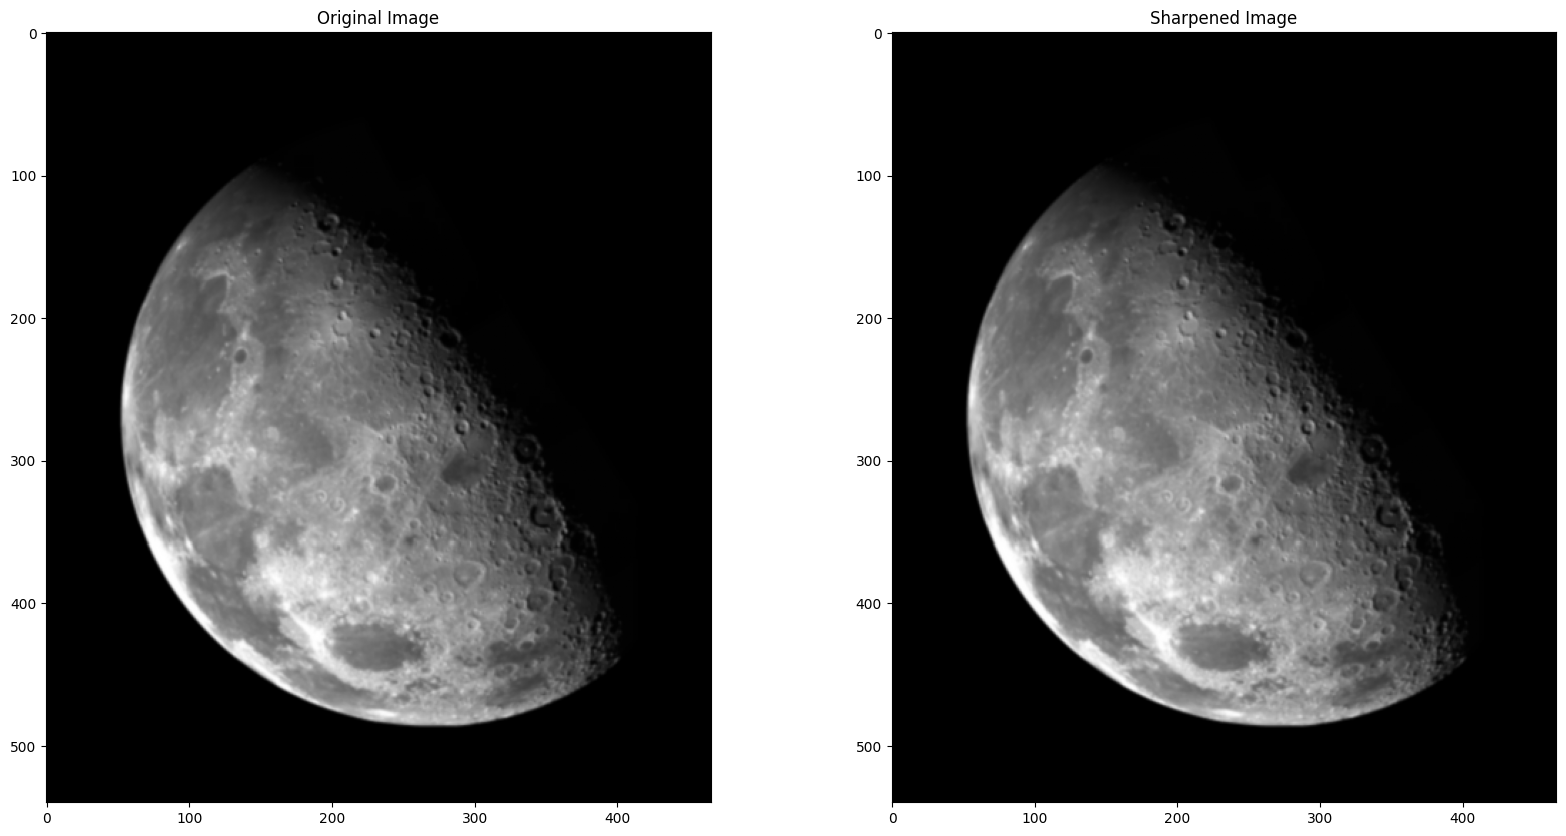

True

In [ ]:
laplacian_image = cv2.multiply(laplacian_image, -1)
newimage = cv2.add(image, laplacian_image)

# Display the original and Laplacian filtered images
plt.figure(figsize=[20, 10])
plt.subplot(121); plt.imshow(image, cmap="gray"); plt.title("Original Image")
plt.subplot(122); plt.imshow(newimage, cmap="gray"); plt.title("Sharpened Image")
plt.show()

cv2.imwrite('sharpen_image_laplacian.jpg', newimage)

LATIHAN:



1.   Lakukan penajaman citra blurry-moon dengan cara yang sama menggunakan beberapa kernel yang berbeda (lihat Slide 31-32)
2.   Lakukan kombinasi filter spasial pada citra skeleton-orig sesuai Slide 36 - Slide 43
3. Tampilkan histogram citra low_contrast.png
4. Lakukan histogram equalization pada citra low_contrast.png
5. Tampilkan histogram setelah histogram equalization

